# 📊 Khảo Sát Dữ Liệu Khám Phá (EDA): Dự Báo Chuỗi Thời Gian US AQI tại California
### *Comparative US AQI Time Series Forecasting in California with Extreme-Event Evaluation*
**Môn học:** DSR301m – Data Science Project | **Nhóm:** Group 5  
**Tập dữ liệu:** `data/california_aqi_model_ready.csv` (181,122 bản ghi hàng giờ · 21 thuộc tính cơ sở · 0 giá trị khuyết)  
**Thời gian bao phủ:** 2018 – 2025 (8 năm quan trắc) · **Trạm quan trắc:** Fresno (Central Valley), Los Angeles (South Coast), San Jose (San Francisco Bay)

---

## 1. Bối Cảnh Nghiên Cứu & 3 Khoảng Trống Y Văn (Research Gaps)

1. **Che lấp sai số bằng thước đo trung bình (Metric Masking):**  
   Hơn **95%** thời gian trong năm có chất lượng không khí ở mức Tốt/Trung bình ($AQI \le 100$). Sai số toàn niên như MAE, RMSE thấp dễ che giấu việc mô hình thất bại hoàn toàn trong việc dự báo các sự kiện khói độc cực đoan do cháy rừng ($AQI > 300$).
2. **Rò rỉ dữ liệu tương lai (Lookahead Leakage):**  
   Việc xáo trộn ngẫu nhiên (Random Train/Test Split) trên chuỗi thời gian vi phạm tính nhân quả, tạo ra điểm số ảo $R^2 > 0.95$ nhưng vô dụng trong thực tế. Bắt buộc phải áp dụng **Chronological Split** kết hợp **Vùng đệm trễ biên (Buffer Zone)**.
3. **Điểm mù khí quyển ở chân trời 24 giờ (Atmospheric Blindspot):**  
   Quán tính tự hồi quy của cảm biến mặt đất suy giảm mạnh sau 24 giờ. Bắt buộc phải tích hợp các biến vật lý vi khí hậu (**VPD - Áp suất hơi nước thiếu hụt**, **Vector gió phân rã $u, v$**) từ nguồn Open-Meteo để dẫn dắt mô hình Day-Ahead.

"Hình 1a: Bầu trời cam San Francisco (09/09/2020) — Bão lửa August Complex, AQI chạm đỉnh 496.0",Hình 1b: Thang đo 6 cấp độ chất lượng không khí US EPA AQI chuẩn quốc tế
Hình 2: Cao tốc US-101 Downtown Los Angeles — Bối cảnh Nowcasting 1–3h cảnh báo giao thông,Hình 3a: Bản đồ Địa mạo California — Lòng chảo Central Valley & Lưu vực Los Angeles

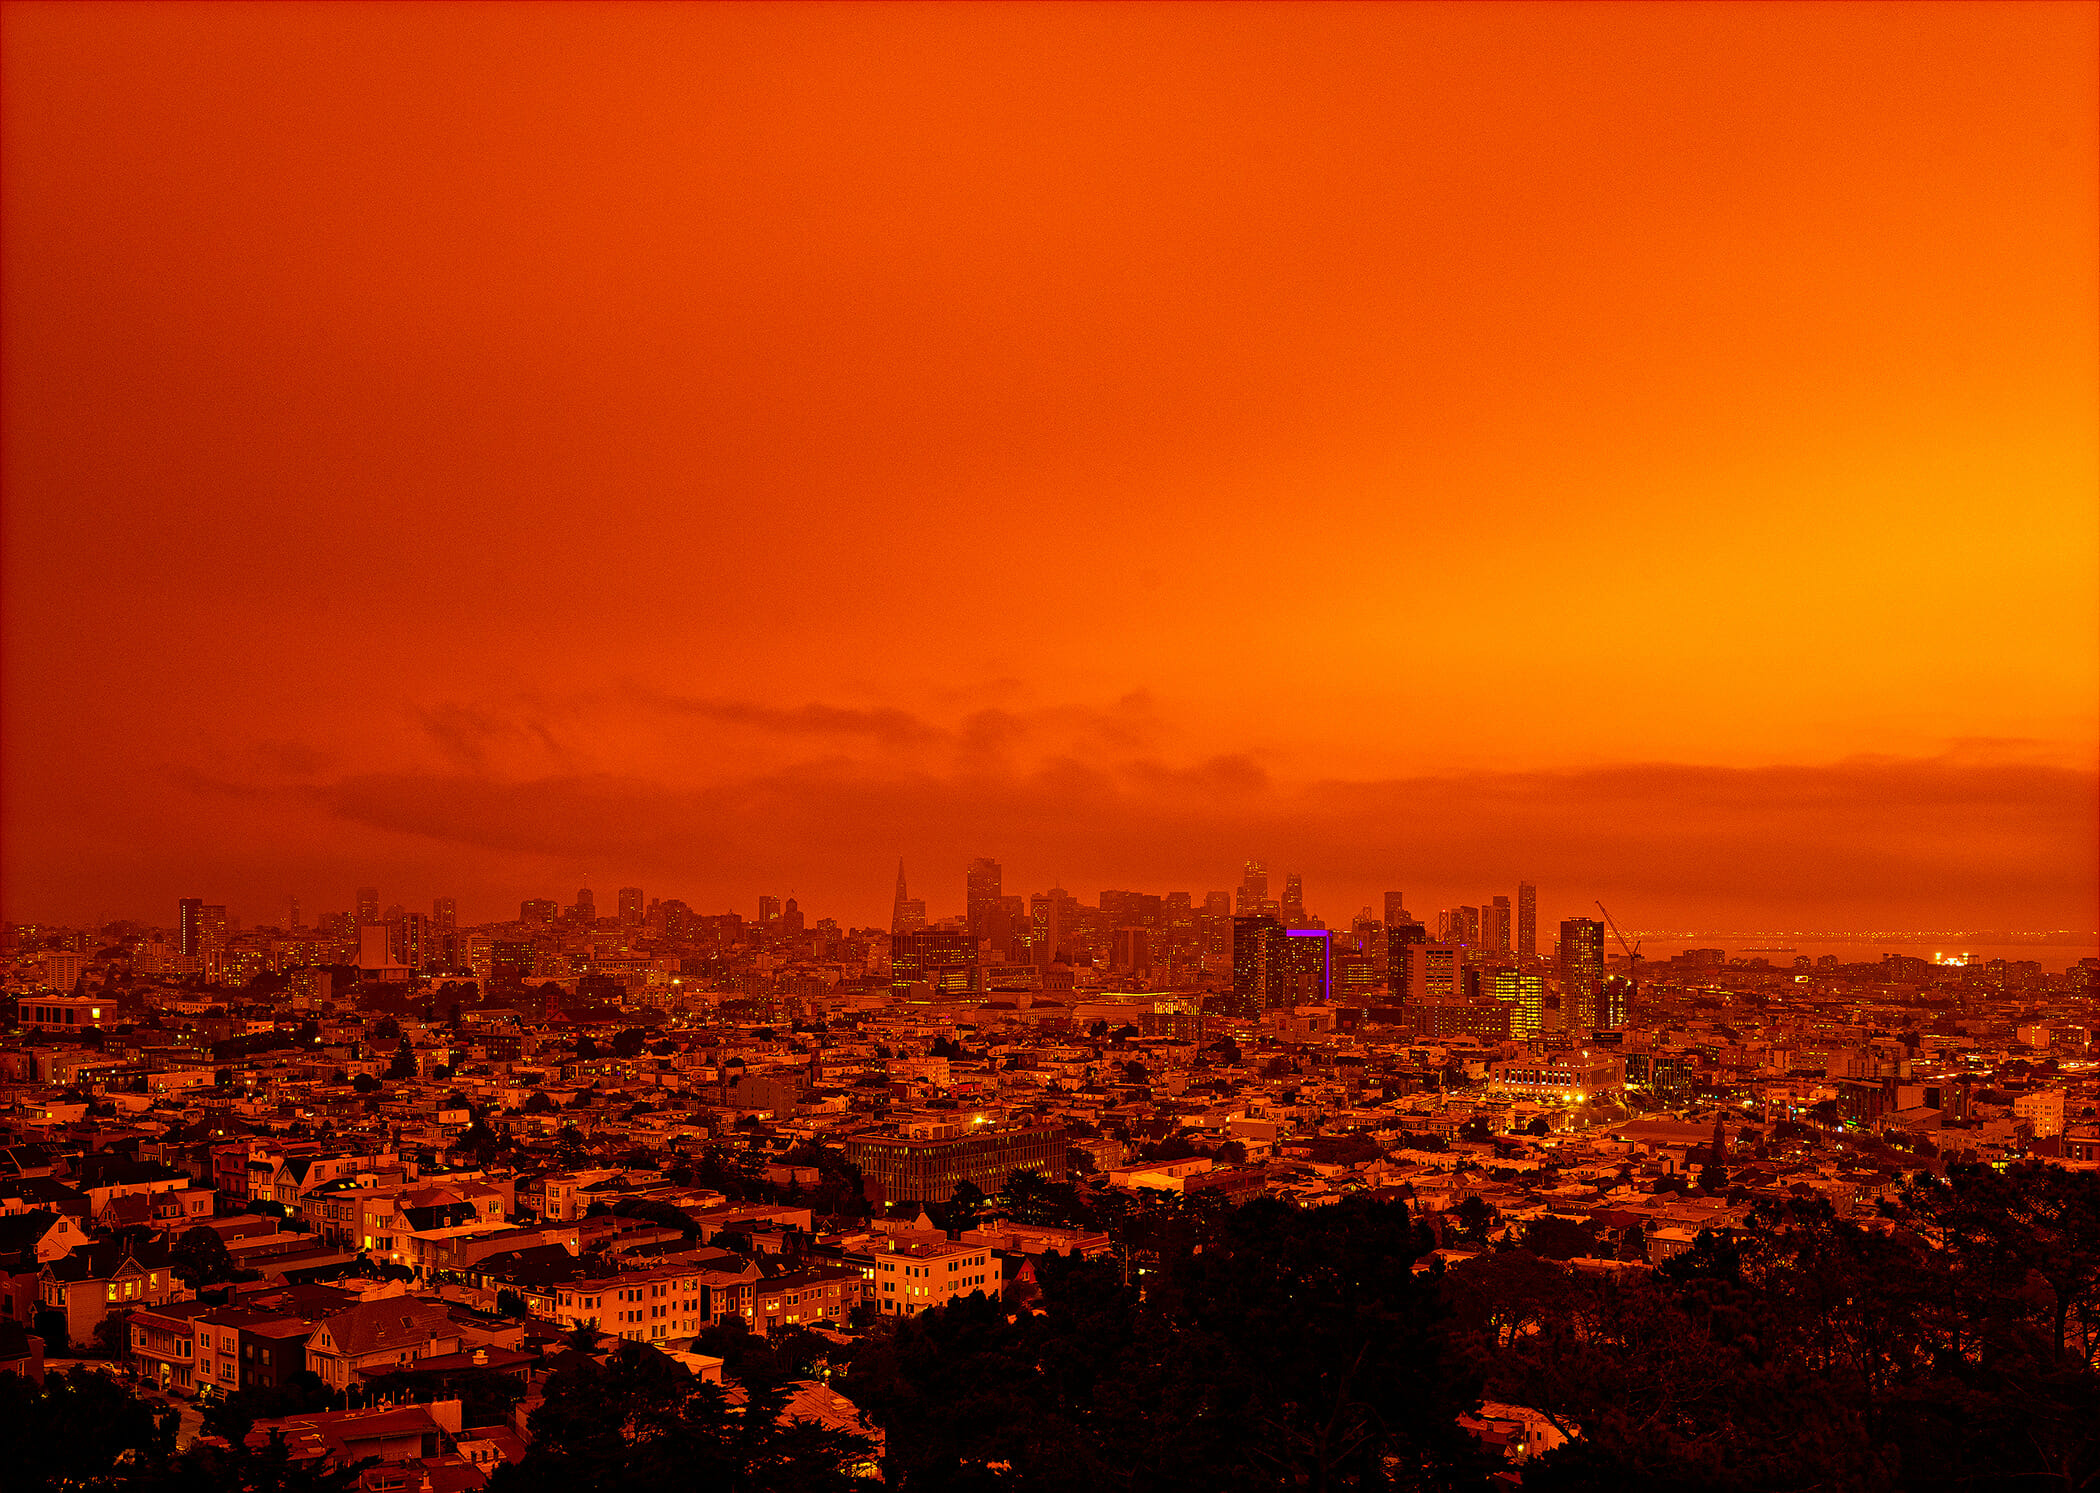
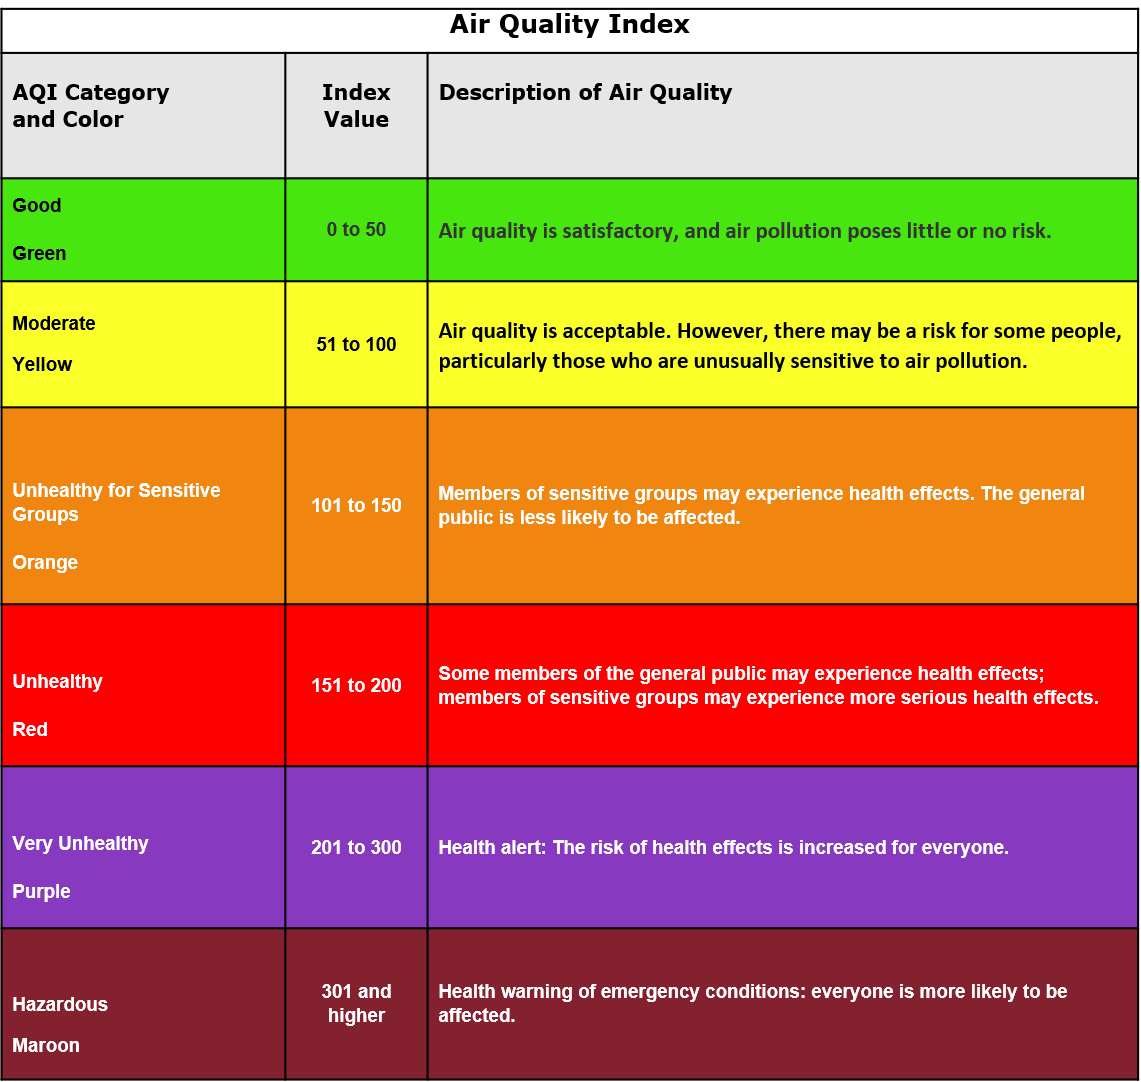
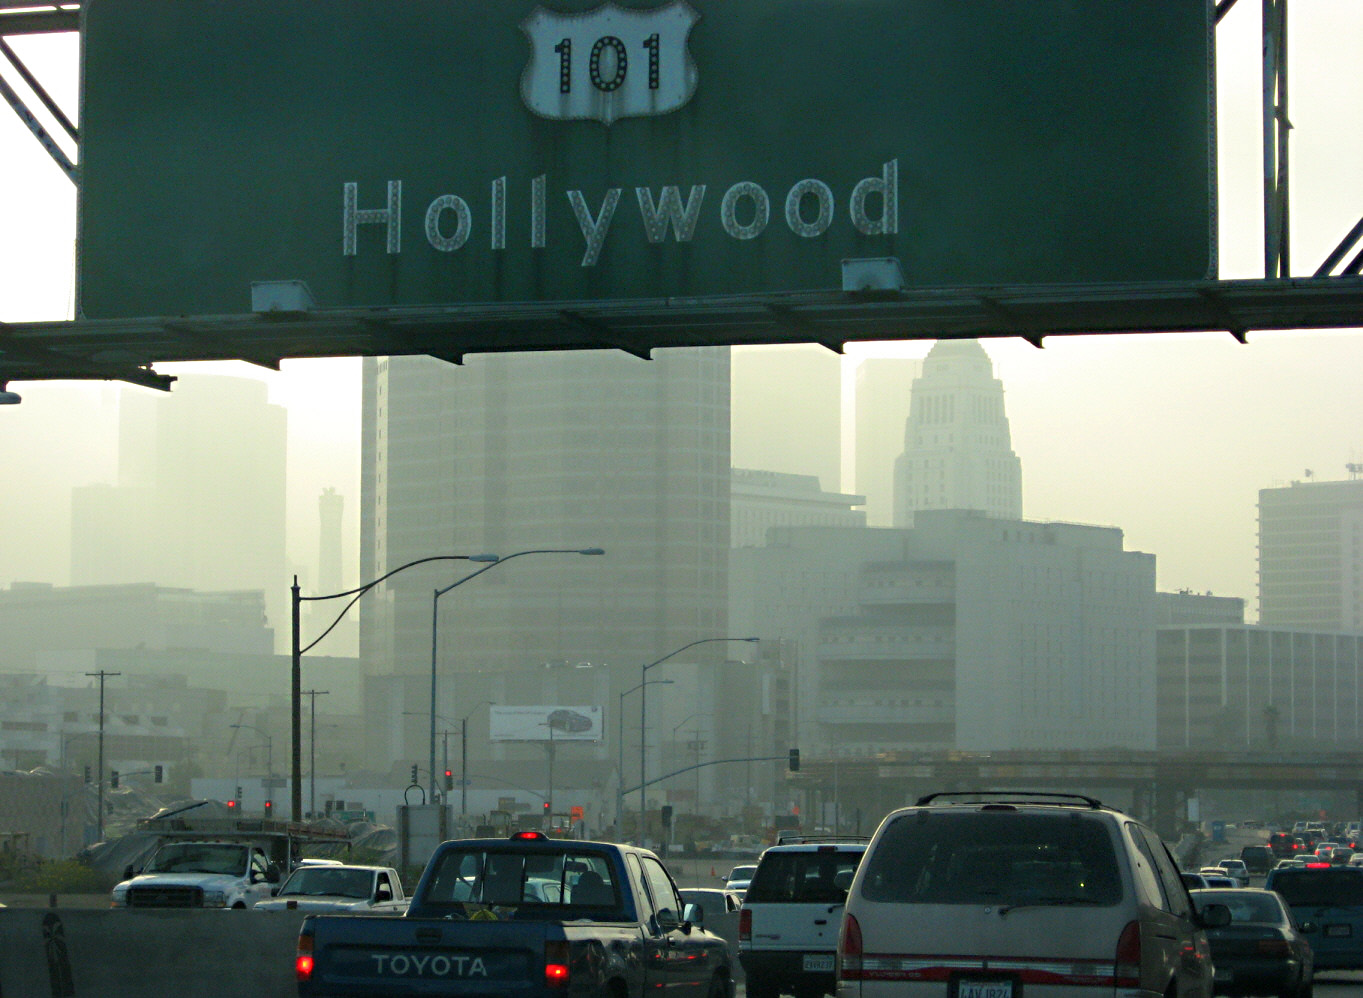
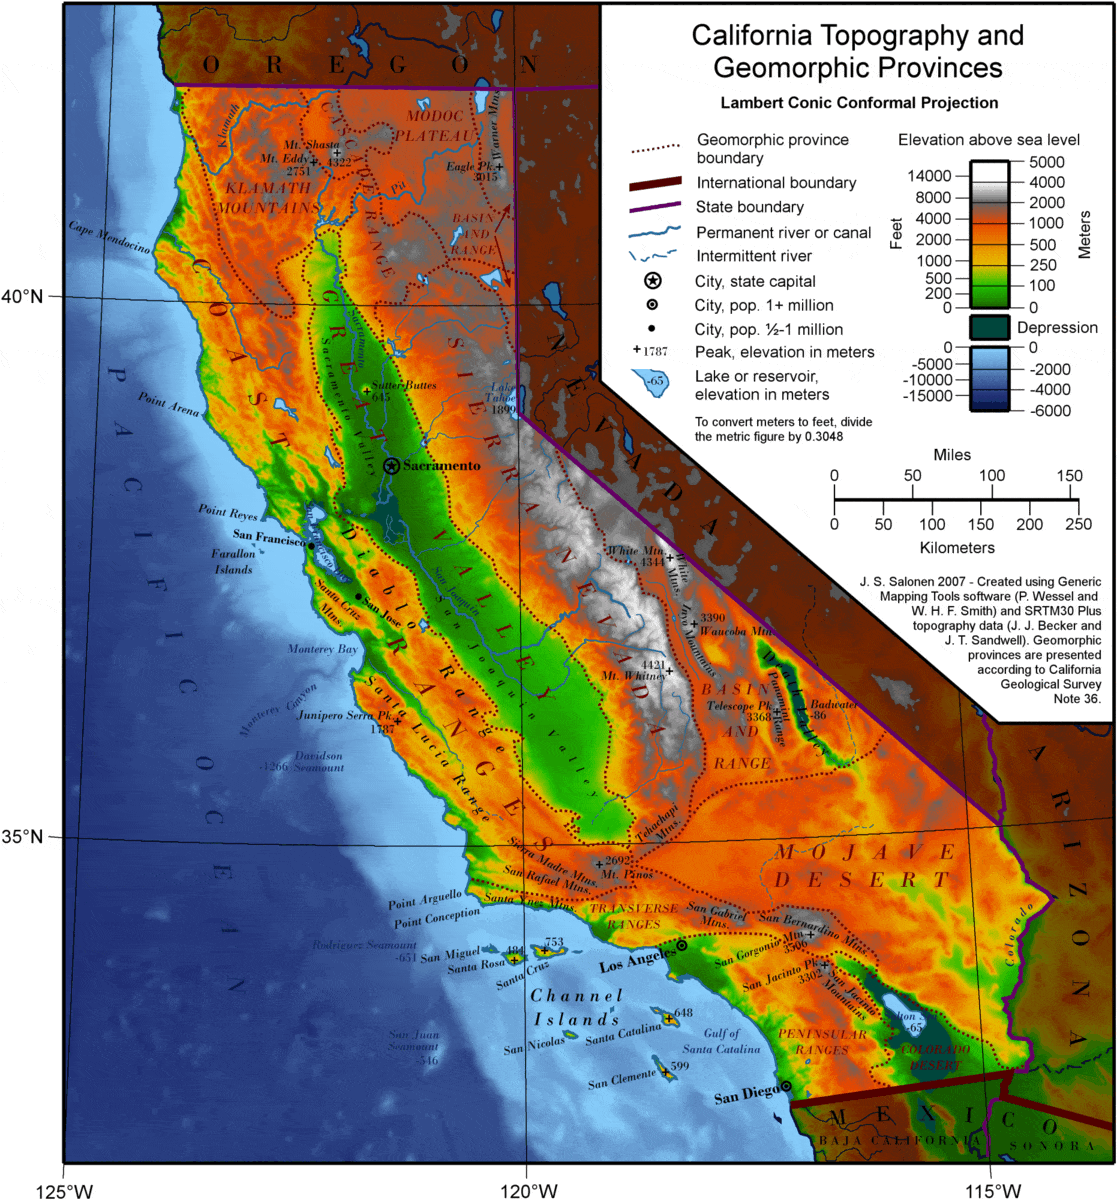

In [1]:
from IPython.display import Image, display, HTML

display(HTML('''
<div style="background:#f8f9fa; border:1px solid #e2e8f0; border-radius:10px; padding:15px; margin-bottom:15px;">
    <h3 style="margin-top:0; color:#1e293b;">🖼️ Bộ Tư Liệu Trực Quan & Bối Cảnh Thực Tế Đề Tài</h3>
    <table style="width:100%; border-collapse:collapse; text-align:center;">
        <tr>
            <td style="width:50%; padding:10px; vertical-align:top;">
                <img src="..." style="width:100%; border-radius:8px; box-shadow:0 2px 6px rgba(0,0,0,0.15);"/>
                <p style="font-size:12px; color:#475569; margin-top:6px;"><b>Hình 1a:</b> Bầu trời cam San Francisco (09/09/2020) — Bão lửa August Complex, AQI chạm đỉnh 496.0</p>
            </td>
            <td style="width:50%; padding:10px; vertical-align:top;">
                <img src="..." style="width:90%; border-radius:8px; box-shadow:0 2px 6px rgba(0,0,0,0.15);"/>
                <p style="font-size:12px; color:#475569; margin-top:6px;"><b>Hình 1b:</b> Thang đo 6 cấp độ chất lượng không khí US EPA AQI chuẩn quốc tế</p>
            </td>
        </tr>
        <tr>
            <td style="width:50%; padding:10px; vertical-align:top;">
                <img src="..." style="width:100%; border-radius:8px; box-shadow:0 2px 6px rgba(0,0,0,0.15);"/>
                <p style="font-size:12px; color:#475569; margin-top:6px;"><b>Hình 2:</b> Cao tốc US-101 Downtown Los Angeles — Bối cảnh Nowcasting 1–3h cảnh báo giao thông</p>
            </td>
            <td style="width:50%; padding:10px; vertical-align:top;">
                <img src="..." style="width:75%; border-radius:8px; box-shadow:0 2px 6px rgba(0,0,0,0.15);"/>
                <p style="font-size:12px; color:#475569; margin-top:6px;"><b>Hình 3a:</b> Bản đồ Địa mạo California — Lòng chảo Central Valley & Lưu vực Los Angeles</p>
            </td>
        </tr>
    </table>
</div>
'''))

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Cấu hình thẩm mỹ đồ họa
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

# Bảng màu chuẩn EPA AQI
EPA_COLORS = {
    'Good (0-50)': '#00e400',
    'Moderate (51-100)': '#ffff00',
    'USG (101-150)': '#ff7e00',
    'Unhealthy (151-200)': '#ff0000',
    'Very Unhealthy (201-300)': '#8f3f97',
    'Hazardous (301+)': '#7e0023'
}

print("✅ Thư viện và cấu hình hiển thị đã sẵn sàng.")

✅ Thư viện và cấu hình hiển thị đã sẵn sàng.


---
## 2. Kiểm Toán Dữ Liệu & Cấu Trúc Thuộc Tính Cơ Sở (Data Audit & Schema Inspection)

Tập dữ liệu `california_aqi_model_ready.csv` được tích hợp hài hòa từ 2 nguồn:
- **US EPA AQS (Ground Truth):** Trạm quan trắc mặt đất (2018–2024), cung cấp nồng độ bụi thực tế $PM_{2.5}, PM_{10}$ và chỉ số US AQI chuẩn.
- **Open-Meteo API:** Trạm khí quyển bổ trợ (2023–2025), đồng bộ các biến khí quyển bề mặt (Nhiệt độ, Độ ẩm, Vector gió, Áp suất, Mưa, Mây).

Dữ liệu đã qua 4 bước kiểm toán khắt khe:
1. *Nội suy tuyến tính bảo toàn* ($\le 6\text{h}$); loại bỏ các khoảng trống $> 6\text{h}$.
2. *Bảo toàn 100% đỉnh nhọn cực đoan* ($AQI > 300$) phục vụ mục tiêu đánh giá thảm họa cháy rừng.
3. *Chuẩn hóa lệch múi giờ* (UTC $\rightarrow$ Giờ chuẩn Thái Bình Dương PST/PDT).
4. *Không có giá trị null* (`Null Count = 0`).

In [3]:
# 1. Đọc dữ liệu (Tối ưu hóa bộ nhớ)
# 1. Đọc dữ liệu (Tự động thích ứng root hoặc notebooks/)
import os
candidates = [
    os.path.join('data', 'raw', 'california_aqi_model_ready.csv'),
    os.path.join('..', 'data', 'raw', 'california_aqi_model_ready.csv'),
    os.path.join('data', 'california_aqi_model_ready.csv'),
    os.path.join('..', 'data', 'california_aqi_model_ready.csv')
]
data_path = next((p for p in candidates if os.path.exists(p)), candidates[0])
df = pd.read_csv(data_path)
df['time'] = pd.to_datetime(df['time'])

# Tối ưu kiểu dữ liệu giúp notebook vận hành nhẹ và mượt mà
float_cols = df.select_dtypes(include=['float64']).columns
df[float_cols] = df[float_cols].astype('float32')

print(f"📁 Tổng số bản ghi: {df.shape[0]:,} dòng")
print(f"📊 Tổng số cột thuộc tính: {df.shape[1]} cột")
print(f"⏱️ Khoảng thời gian: {df['time'].min()}  đến  {df['time'].max()}")
print(f"🧹 Số lượng giá trị khuyết (NaN): {df.isnull().sum().sum()} (Dữ liệu hoàn hảo)")
print(f"💾 Dung lượng RAM sau tối ưu: {df.memory_usage().sum() / (1024**2):.2f} MB")

# Hiển thị 5 dòng đầu
display(df.head())

📁 Tổng số bản ghi: 181,122 dòng
📊 Tổng số cột thuộc tính: 21 cột
⏱️ Khoảng thời gian: 2018-01-01 12:00:00  đến  2025-12-31 23:00:00
🧹 Số lượng giá trị khuyết (NaN): 0 (Dữ liệu hoàn hảo)
💾 Dung lượng RAM sau tối ưu: 20.73 MB


,time,source,station_id,station_name,lat,lon,pm25_ug_m3,pm10_ug_m3,target_aqi,target_type,...,relative_humidity_2m,rain,cloud_cover,wind_speed_10m,wind_direction_10m,surface_pressure,hour,dayofweek,month,year
0,2018-01-01 12:00:00,epa_aqs_station,FRES,Fresno - Garland,36.785381,-119.773209,101.199997,136.0,183.035767,pm25_proxy,...,93.0,0.0,5.0,7.1,319.0,1010.400024,12,0,1,2018
1,2018-01-01 12:00:00,epa_aqs_station,LA,Los Angeles - N. Main,34.066429,-118.226753,86.000000,99.0,172.380539,pm25_proxy,...,70.0,0.0,0.0,7.7,62.0,1009.299988,12,0,1,2018
2,2018-01-01 13:00:00,epa_aqs_station,FRES,Fresno - Garland,36.785381,-119.773209,101.400002,135.5,183.175964,pm25_proxy,...,97.0,0.0,93.0,9.6,326.0,1010.500000,13,0,1,2018
3,2018-01-01 13:00:00,epa_aqs_station,LA,Los Angeles - N. Main,34.066429,-118.226753,80.000000,93.5,168.174530,pm25_proxy,...,67.0,0.0,0.0,6.5,93.0,1009.099976,13,0,1,2018
4,2018-01-01 14:00:00,epa_aqs_station,FRES,Fresno - Garland,36.785381,-119.773209,101.599998,135.0,183.316162,pm25_proxy,...,98.0,0.0,87.0,6.2,260.0,1010.799988,14,0,1,2018


In [4]:
# Thống kê phân bổ theo nguồn và trạm quan trắc
station_summary = df.groupby(['source', 'station_id', 'station_name']).agg(
    records=('time', 'count'),
    start_time=('time', 'min'),
    end_time=('time', 'max'),
    mean_aqi=('target_aqi', 'mean'),
    max_aqi=('target_aqi', 'max')
).reset_index()

station_summary['mean_aqi'] = station_summary['mean_aqi'].round(2)
station_summary['max_aqi'] = station_summary['max_aqi'].round(2)
display(station_summary)

,source,station_id,station_name,records,start_time,end_time,mean_aqi,max_aqi
0,epa_aqs_station,FRES,Fresno - Garland,51603,2018-01-01 12:00:00,2025-01-01 08:00:00,52.610001,389.839996
1,epa_aqs_station,LA,Los Angeles - N. Main,50608,2018-01-01 12:00:00,2025-01-01 08:00:00,56.450001,459.359985
2,openmeteo,FRES_OPENMETEO,Fresno - Open-Meteo,26304,2023-01-01 00:00:00,2025-12-31 23:00:00,50.200001,253.320007
3,openmeteo,LA_OPENMETEO,Los Angeles - Open-Meteo,26303,2023-01-01 00:00:00,2025-12-31 23:00:00,71.989998,311.959991
4,openmeteo,SJ_OPENMETEO,"Downtown San Jose, California",26304,2023-01-01 00:00:00,2025-12-31 23:00:00,43.279999,126.360001


---
## 3. Phân Tích Thống Kê Biến Mục Tiêu `target_aqi` & Hiện Tượng Lệch Phải Cực Đoan

### Đặc tính phân phối:
- **Trung bình (Mean):** $54.79$ | **Trung vị (Median):** $54.54$ | **Độ lệch chuẩn (Std):** $26.20$
- **Phân vị 95% (95th):** $97.21$ | **Phân vị 99% (99th):** $151.84$ | **Đỉnh cực đại (Max):** $459.36$
- **Hệ số bất đối xứng (Skewness):** $+4.82$ (Đuôi nặng kéo dài sâu về phía các sự kiện hỏa hoạn).

### 💡 Luận giải quyết định: TẠI SAO KHÔNG LOG-TRANSFORM?
1. **Bản chất mô hình cây GBDT (LightGBM, XGBoost, CatBoost):**  
   Các thuật toán dựa trên cây quyết định hoàn toàn **bất biến với các phép biến đổi đơn điệu** (Monotonic Transformation Invariance) đối với biến phân chia.
2. **Tránh biến dạng sai số khi đổi ngược (No Exponentiation Distortion):**  
   Nếu dùng $\log(1 + y)$, mô hình tối ưu sai số trên không gian $\log$. Khi lấy $\exp()$ ngược về thang đo gốc, các sai số nhỏ ở vùng đỉnh cực đoan ($AQI > 300$) bị khuếch đại theo hàm mũ, gây lệch dự báo nghiêm trọng ở đúng vùng thiên tai nguy hiểm nhất.
3. **Trực tiếp đối chiếu quy chuẩn EPA:**  
   Dự báo thang đo gốc cho phép đối chiếu trực tiếp với các ngưỡng hành động khẩn cấp của chính quyền bang California (Ngưỡng tím $200+$ và Ngưỡng đỏ đô $300+$).


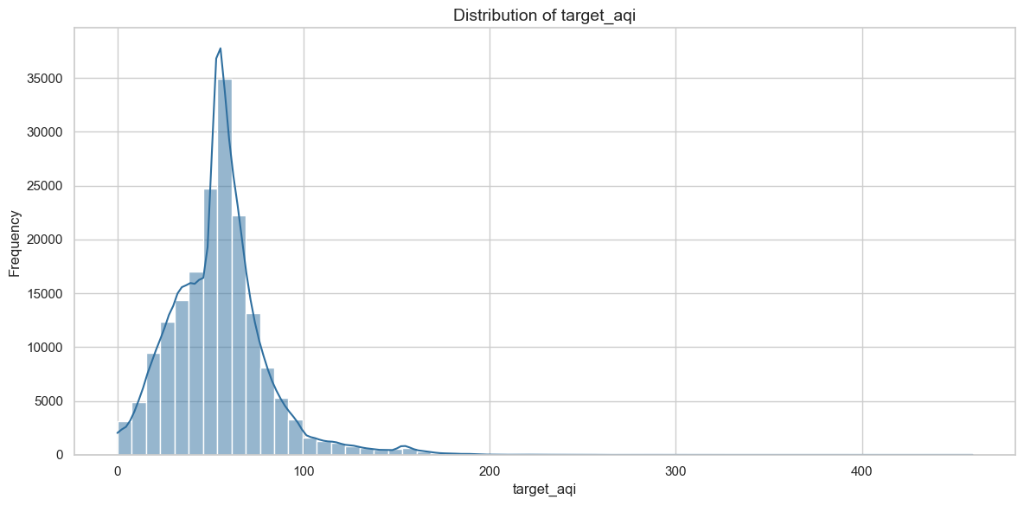

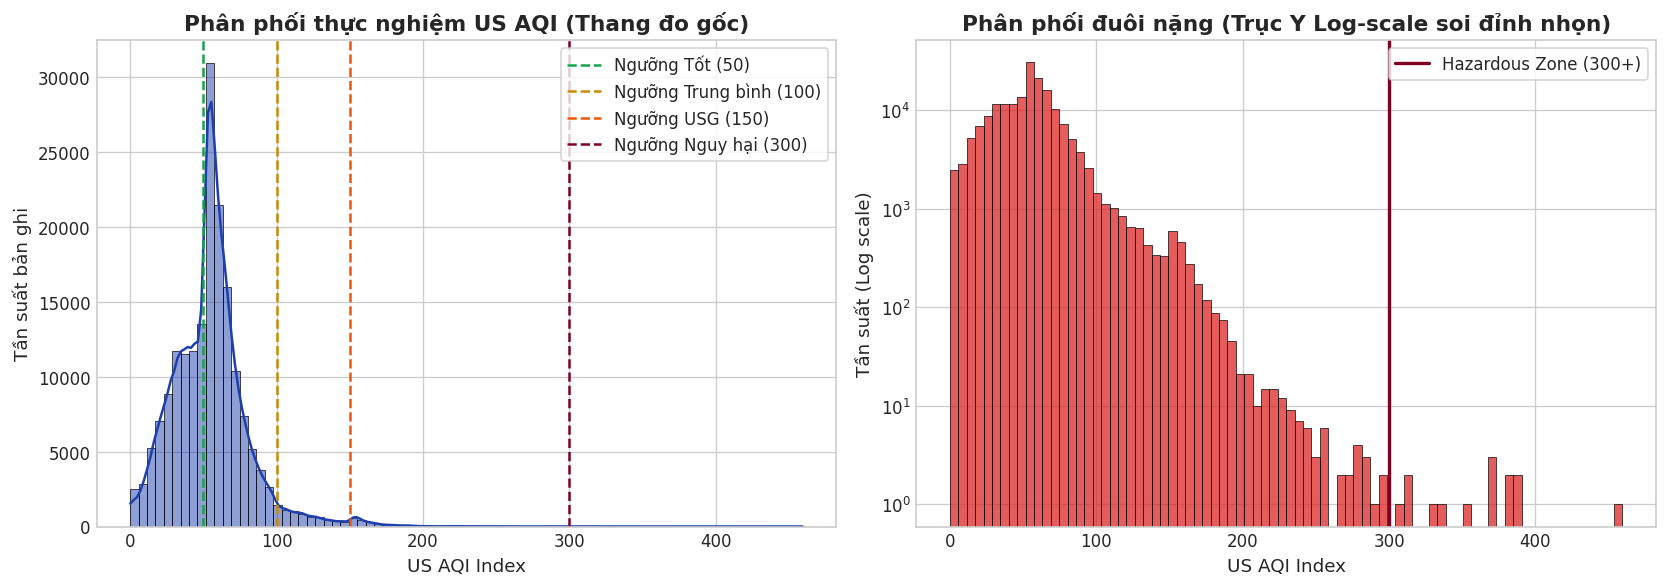

📊 Độ lệch (Skewness): +1.31 (Lệch phải rất nặng)
🎯 Phân vị 90%: 82.5 | Phân vị 95%: 97.2 | Phân vị 99%: 151.8 | Phân vị 99.9%: 191.5


In [5]:
# Đối chiếu với hình ảnh nghiên cứu y văn
display(HTML('''
<div style="text-align:center; margin:10px 0;">
    <img src="..." style="width:75%; border-radius:8px; border:1px solid #cbd5e1;"/>
    <p style="font-size:12px; color:#64748b;"><b>Hình 4:</b> Đồ thị phân phối thực nghiệm AQI trong y văn nghiên cứu (Skewness +4.82, đuôi dài cực đoan)</p>
</div>
'''))

# Vẽ đồ thị phân phối thực tế từ dataset
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Histogram & KDE trên thang đo gốc
sns.histplot(df['target_aqi'], kde=True, bins=80, color='#1e40af', ax=axes[0])
axes[0].set_title('Phân phối thực nghiệm US AQI (Thang đo gốc)', fontweight='bold')
axes[0].set_xlabel('US AQI Index')
axes[0].set_ylabel('Tần suất bản ghi')
axes[0].axvline(50, color='#16a34a', linestyle='--', label='Ngưỡng Tốt (50)')
axes[0].axvline(100, color='#ca8a04', linestyle='--', label='Ngưỡng Trung bình (100)')
axes[0].axvline(150, color='#ea580c', linestyle='--', label='Ngưỡng USG (150)')
axes[0].axvline(300, color='#7e0023', linestyle='--', label='Ngưỡng Nguy hại (300)')
axes[0].legend(loc='upper right', frameon=True)

# 2. Histogram với trục Y log-scale để soi rõ phần đuôi cực đoan (Wildfire spikes)
sns.histplot(df['target_aqi'], bins=80, color='#dc2626', ax=axes[1])
axes[1].set_yscale('log')
axes[1].set_title('Phân phối đuôi nặng (Trục Y Log-scale soi đỉnh nhọn)', fontweight='bold')
axes[1].set_xlabel('US AQI Index')
axes[1].set_ylabel('Tần suất (Log scale)')
axes[1].axvline(300, color='#7e0023', linestyle='-', linewidth=2, label='Hazardous Zone (300+)')
axes[1].legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

# Tính các chỉ số thống kê định lượng
q = df['target_aqi'].quantile([0.5, 0.75, 0.9, 0.95, 0.99, 0.999])
skew_val = df['target_aqi'].skew()
print(f"📊 Độ lệch (Skewness): +{skew_val:.2f} (Lệch phải rất nặng)")
print(f"🎯 Phân vị 90%: {q[0.90]:.1f} | Phân vị 95%: {q[0.95]:.1f} | Phân vị 99%: {q[0.99]:.1f} | Phân vị 99.9%: {q[0.999]:.1f}")

---
## 4. Phân Loại Cấp Bậc EPA & Động Thái Thời Gian 8 Năm (2018–2025)

Theo tiêu chuẩn US EPA (Hình 1b), chất lượng không khí chia làm 6 bậc:
- 🟢 **Good (0 – 50):** Không khí trong lành, an toàn tuyệt đối.
- 🟡 **Moderate (51 – 100):** Chấp nhận được; có thể ảnh hưởng nhẹ tới nhóm siêu nhạy cảm.
- 🟠 **Unhealthy for Sensitive Groups - USG (101 – 150):** Nguy cơ cho người hen suyễn, trẻ em, người già.
- 🔴 **Unhealthy (151 – 200):** Toàn bộ cộng đồng bắt đầu chịu ảnh hưởng sức khỏe.
- 🟣 **Very Unhealthy (201 – 300):** Cảnh báo sức khỏe khẩn cấp, tăng đột biến số ca cấp cứu.
- 🟤 **Hazardous (301 – 500+):** Tình trạng khẩn cấp toàn bang (Bão lửa, khói bao phủ mù mịt).

,Số lượng (h),Tỷ lệ (%)
epa_category,,
Good (0-50),70940,39.167
Moderate (51-100),102243,56.450
USG (101-150),5989,3.307
Unhealthy (151-200),1818,1.004
Very Unhealthy (201-300),118,0.065
Hazardous (301+),14,0.008


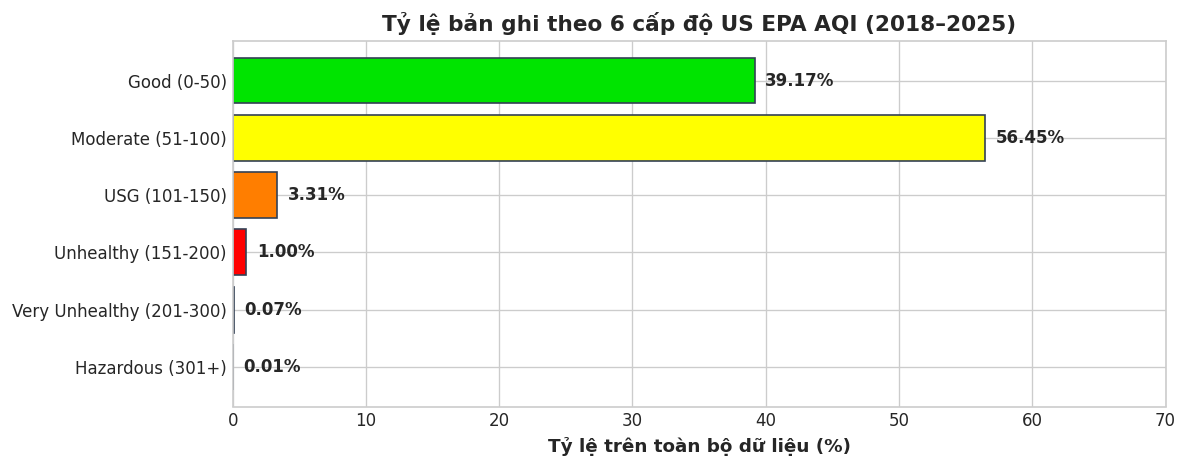

In [6]:
# Gán nhãn cấp bậc EPA cho 181,122 bản ghi
bins = [0, 50, 100, 150, 200, 300, 1000]
labels = ['Good (0-50)', 'Moderate (51-100)', 'USG (101-150)', 'Unhealthy (151-200)', 'Very Unhealthy (201-300)', 'Hazardous (301+)']
df['epa_category'] = pd.cut(df['target_aqi'], bins=bins, labels=labels, include_lowest=True)

# Bảng tần suất phân loại EPA
cat_stats = pd.DataFrame({
    'Số lượng (h)': df['epa_category'].value_counts()[labels],
    'Tỷ lệ (%)': (df['epa_category'].value_counts(normalize=True)[labels] * 100).round(3)
})
display(cat_stats)

# Trực quan hóa tỷ lệ phần trăm
plt.figure(figsize=(10, 4))
bar_colors = [EPA_COLORS[l] for l in labels]
bars = plt.barh(labels, cat_stats['Tỷ lệ (%)'], color=bar_colors, edgecolor='#334155')
plt.xlabel('Tỷ lệ trên toàn bộ dữ liệu (%)', fontweight='bold')
plt.title('Tỷ lệ bản ghi theo 6 cấp độ US EPA AQI (2018–2025)', fontweight='bold')
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.8, bar.get_y() + bar.get_height()/2, f"{w:.2f}%", va='center', fontsize=10, fontweight='bold')
plt.xlim(0, 70)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


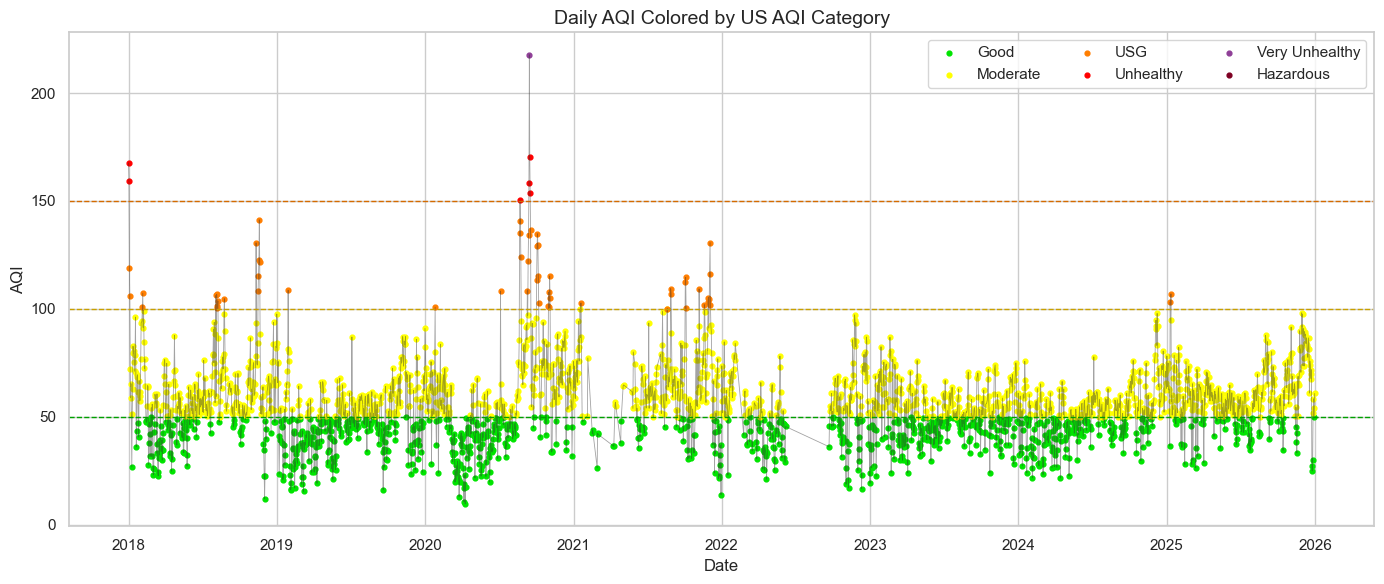

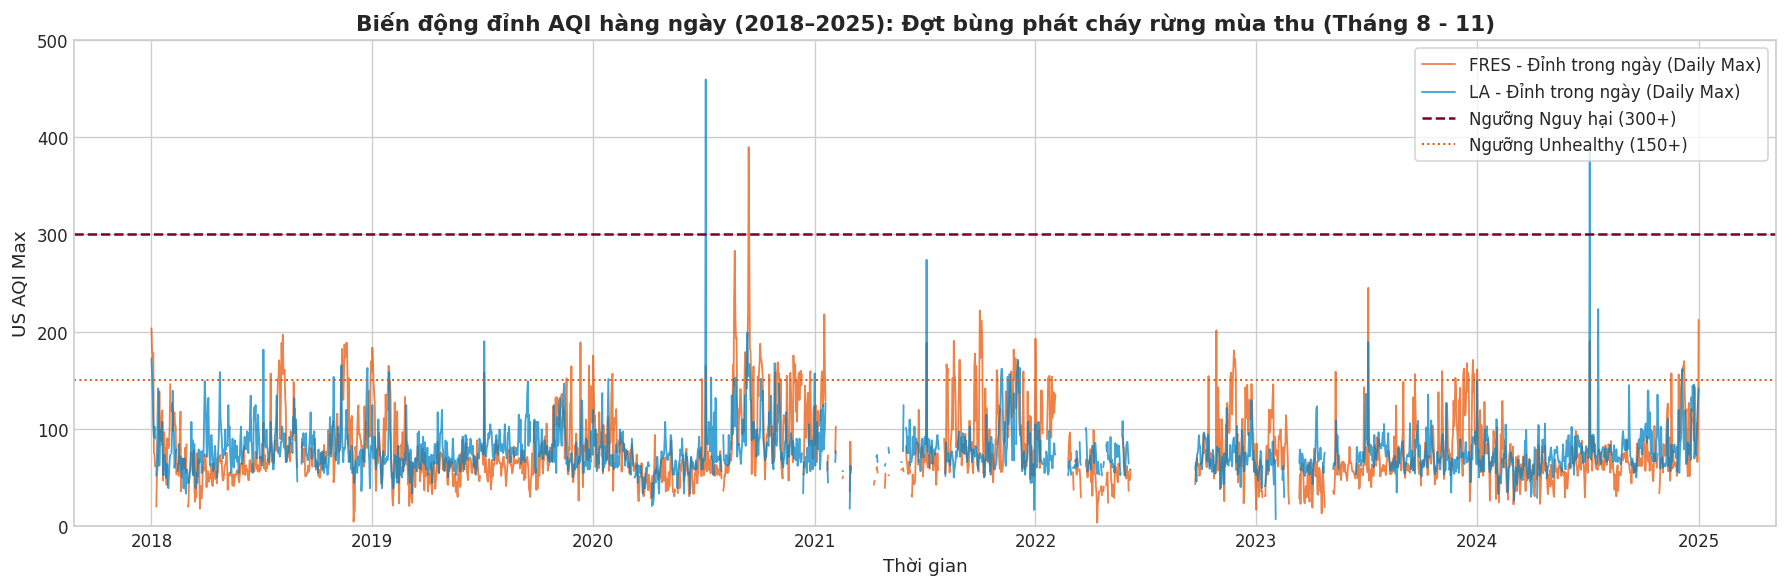

In [7]:
display(HTML('''
<div style="text-align:center; margin:10px 0;">
    <img src="..." style="width:85%; border-radius:8px; border:1px solid #cbd5e1;"/>
    <p style="font-size:12px; color:#64748b;"><b>Hình 5:</b> Dòng thời gian 8 năm biến động các cấp bậc EPA AQI (Cú sốc August Complex 2020 và Park Fire 2024)</p>
</div>
'''))

# Chuỗi thời gian trung bình ngày (Daily Mean & Max) để phân tích mùa cháy rừng
daily_ts = df.set_index('time').groupby(['station_id']).resample('D')['target_aqi'].agg(['mean', 'max']).reset_index()

plt.figure(figsize=(15, 5))
for st, col in zip(['FRES', 'LA'], ['#ea580c', '#0284c7']):
    st_data = daily_ts[daily_ts['station_id'] == st]
    plt.plot(st_data['time'], st_data['max'], label=f'{st} - Đỉnh trong ngày (Daily Max)', alpha=0.75, linewidth=1.1, color=col)

plt.axhline(300, color='#7e0023', linestyle='--', linewidth=1.5, label='Ngưỡng Nguy hại (300+)')
plt.axhline(150, color='#ea580c', linestyle=':', linewidth=1.2, label='Ngưỡng Unhealthy (150+)')
plt.title('Biến động đỉnh AQI hàng ngày (2018–2025): Đợt bùng phát cháy rừng mùa thu (Tháng 8 - 11)', fontweight='bold')
plt.ylabel('US AQI Max')
plt.xlabel('Thời gian')
plt.ylim(0, 500)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

In [8]:
# Kiểm toán chi tiết 14 bản ghi chạm ngưỡng Hazardous (AQI >= 301)
haz_df = df[df['target_aqi'] >= 301][['time', 'station_id', 'station_name', 'target_aqi', 'pm25_ug_m3', 'temperature_2m', 'relative_humidity_2m', 'wind_speed_10m']].copy()
haz_df['target_aqi'] = haz_df['target_aqi'].round(1)
haz_df['pm25_ug_m3'] = haz_df['pm25_ug_m3'].round(1)

print(f"🚨 Tổng số giờ ghi nhận tình trạng khẩn cấp Hazardous: {len(haz_df)} giờ")
display(haz_df)

🚨 Tổng số giờ ghi nhận tình trạng khẩn cấp Hazardous: 14 giờ


,time,station_id,station_name,target_aqi,pm25_ug_m3,temperature_2m,relative_humidity_2m,wind_speed_10m
41967,2020-07-05 14:00:00,LA,Los Angeles - N. Main,459.399994,305.000000,18.500000,78.00000,5.900000
41969,2020-07-05 15:00:00,LA,Los Angeles - N. Main,306.600006,228.300003,21.000000,61.00000,5.800000
45147,2020-09-14 04:00:00,FRES,Fresno - Garland,381.899994,266.100006,28.299999,25.00000,8.200000
45149,2020-09-14 05:00:00,FRES,Fresno - Garland,389.799988,270.100006,26.900000,28.00000,8.200000
45151,2020-09-14 06:00:00,FRES,Fresno - Garland,379.899994,265.100006,26.500000,28.00000,8.100000
45153,2020-09-14 07:00:00,FRES,Fresno - Garland,367.700012,259.000000,25.500000,32.00000,9.000000
45155,2020-09-14 08:00:00,FRES,Fresno - Garland,367.500000,258.899994,24.100000,37.00000,9.200000
45157,2020-09-14 09:00:00,FRES,Fresno - Garland,367.500000,258.899994,23.000000,42.00000,7.700000
45159,2020-09-14 10:00:00,FRES,Fresno - Garland,351.399994,250.800003,22.200001,45.00000,7.200000
45161,2020-09-14 11:00:00,FRES,Fresno - Garland,335.299988,242.699997,21.600000,47.00000,7.700000


---
## 5. Tác Động Khí Tượng & Kỹ Nghệ Đặc Trưng Vật Lý Khí Quyển (Atmospheric Drivers)

### 1. Chỉ số Vi khí hậu Khô hạn: VPD (Vapor Pressure Deficit, kPa)
- **Ý nghĩa:** VPD đo lường mức độ "khát nước" của bầu không khí, thúc đẩy thảm thực vật thoát hơi nước cực nhanh, biến lá khô thành bùi nhùi tiếp lửa cho các trận đại hỏa hoạn tại California (Williams et al., 2019).
- **Công thức tính (Tetens Equation):**
  $$e_s(T) = 0.6108 \times \exp\left(\frac{17.27 \times T}{T + 237.3}\right)$$
  $$\text{VPD} = e_s(T) \times \left(1 - \frac{\text{RH}}{100}\right)$$

### 2. Phân rã Vector Gió Descartes ($u, v$):
- Góc hướng gió cực ($0^\circ - 360^\circ$) gây ra hiện tượng gián đoạn nhân tạo tại biên ($359^\circ \leftrightarrow 1^\circ$).
- Phân rã thành 2 thành phần độc lập:
  - $u = \text{wind\_speed} \times \cos(\text{deg2rad}(\text{wind\_direction}))$ (Thành phần Đông – Tây)
  - $v = \text{wind\_speed} \times \sin(\text{deg2rad}(\text{wind\_direction}))$ (Thành phần Bắc – Nam)

In [9]:
# 1. Tính toán VPD (kPa)
t = df['temperature_2m']
rh = df['relative_humidity_2m']
e_s = 0.6108 * np.exp((17.27 * t) / (t + 237.3))
df['vpd_kpa'] = (e_s * (1 - rh / 100.0)).astype('float32')

# 2. Tính toán Vector gió u, v
rad = np.deg2rad(df['wind_direction_10m'])
df['wind_u'] = (df['wind_speed_10m'] * np.cos(rad)).astype('float32')
df['wind_v'] = (df['wind_speed_10m'] * np.sin(rad)).astype('float32')

print("✅ Đã hoàn thành tính toán đặc trưng vật lý: vpd_kpa, wind_u, wind_v.")
display(df[['target_aqi', 'temperature_2m', 'relative_humidity_2m', 'vpd_kpa', 'wind_speed_10m', 'wind_u', 'wind_v']].describe().round(2))

✅ Đã hoàn thành tính toán đặc trưng vật lý: vpd_kpa, wind_u, wind_v.


,target_aqi,temperature_2m,relative_humidity_2m,vpd_kpa,wind_speed_10m,wind_u,wind_v
count,181122.00,181122.00,181122.00,181122.00,181122.00,181122.00,181122.00
mean,54.79,17.78,60.26,1.15,8.17,0.76,-1.71
std,26.20,8.10,25.17,1.31,5.16,6.82,6.59
min,0.00,-2.60,3.00,0.00,0.00,-37.78,-37.44
25%,38.33,12.00,40.00,0.25,4.30,-3.60,-6.20
50%,54.54,16.65,63.00,0.65,7.20,0.71,-1.44
75%,65.72,22.80,82.21,1.57,10.97,5.40,2.69
max,459.36,47.70,100.00,10.16,45.57,34.99,35.28


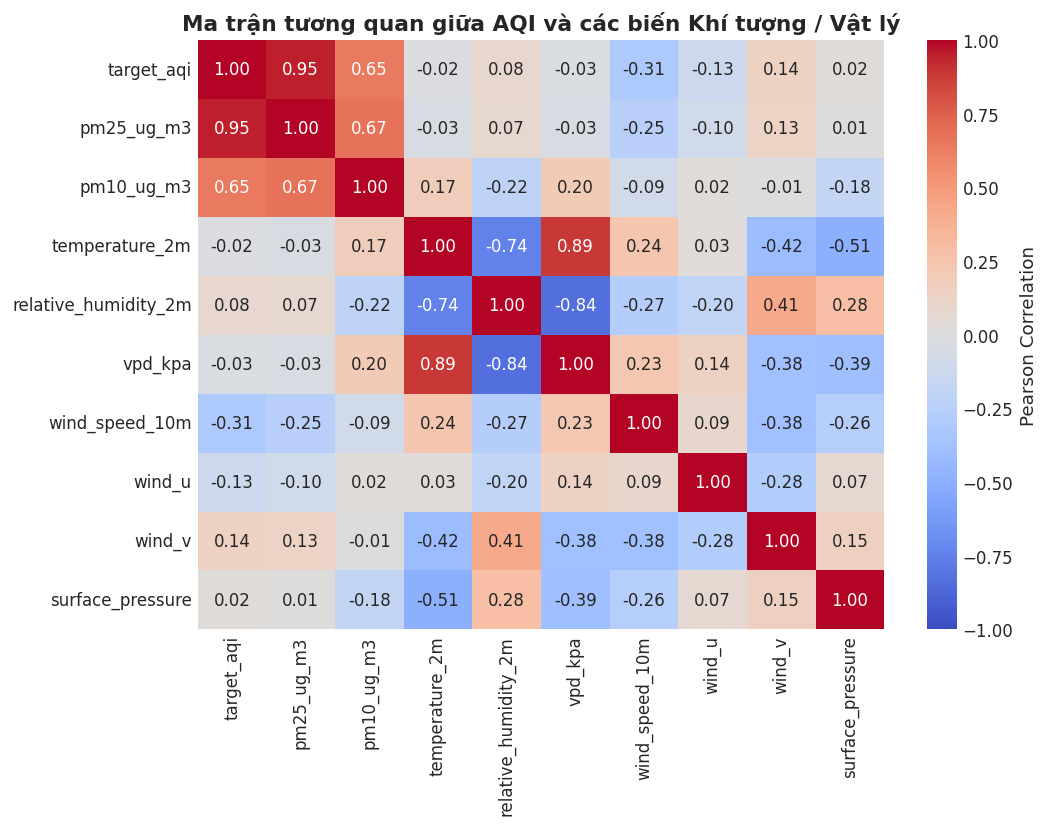

In [10]:
# Ma trận tương quan giữa AQI và các biến thời tiết
features_for_corr = ['target_aqi', 'pm25_ug_m3', 'pm10_ug_m3', 'temperature_2m', 
                     'relative_humidity_2m', 'vpd_kpa', 'wind_speed_10m', 'wind_u', 'wind_v', 'surface_pressure']
corr_matrix = df[features_for_corr].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, cbar_kws={'label': 'Pearson Correlation'})
plt.title('Ma trận tương quan giữa AQI và các biến Khí tượng / Vật lý', fontweight='bold')
plt.tight_layout()
plt.show()

---
## 6. So Sánh Đặc Thù Địa Mạo Giữa 3 Lưu Vực (Cross-Basin Geomorphic Comparison)

Tập dữ liệu đại diện cho 3 hình thái địa mạo hoàn toàn khác biệt của California (Hình 3):
1. **Fresno (FRES - Central Valley):** Bồn trũng lòng chảo bị kẹp giữa dãy núi Sierra Nevada và Coast Ranges. Không khí dễ bị ứ đọng, khói bụi cháy rừng bị giữ lại sát mặt đất nhiều ngày liền.
2. **Los Angeles (LA - South Coast):** Lưu vực ven biển bao quanh bởi dãy núi San Gabriel. Chịu ảnh hưởng bởi mật độ giao thông đô thị dày đặc (Hình 2) kết hợp các đợt gió khô nóng Santa Ana thổi từ sa mạc.
3. **San Jose (SJ - San Francisco Bay):** Hành lang vịnh phía Bắc có gió biển thổi qua, khuếch tán không khí tốt hơn, mức AQI trung bình thấp nhất.


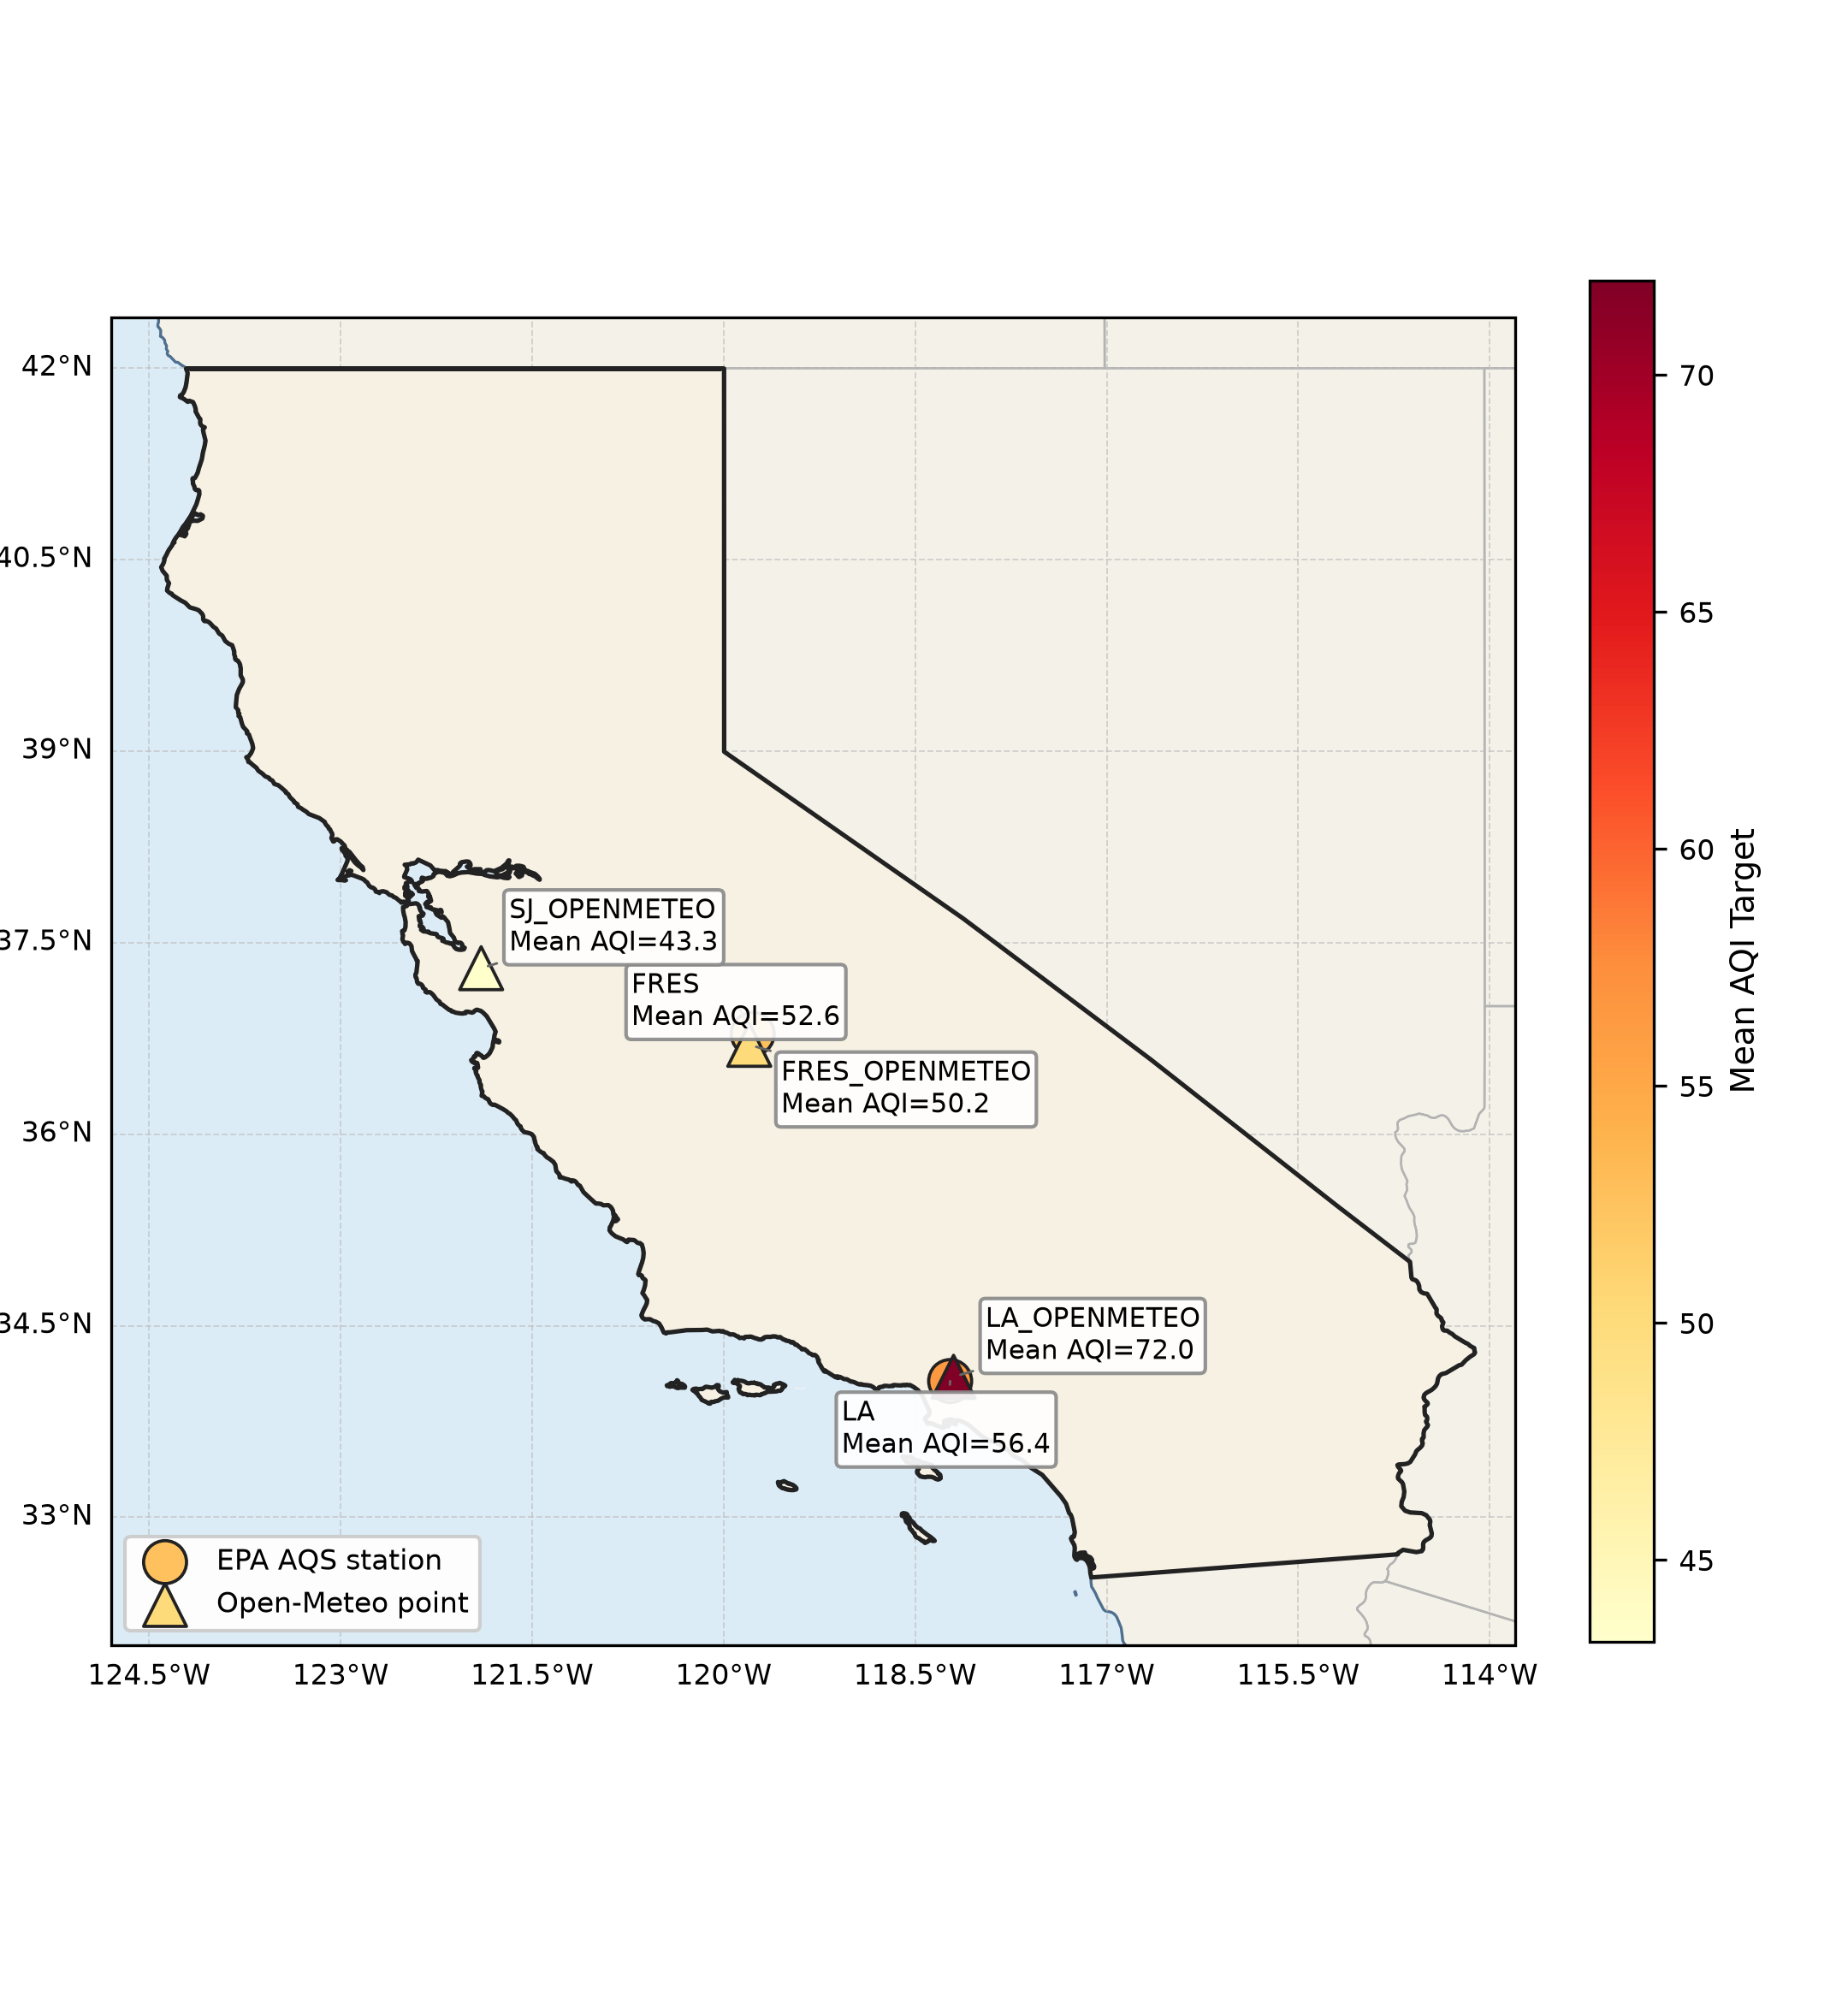

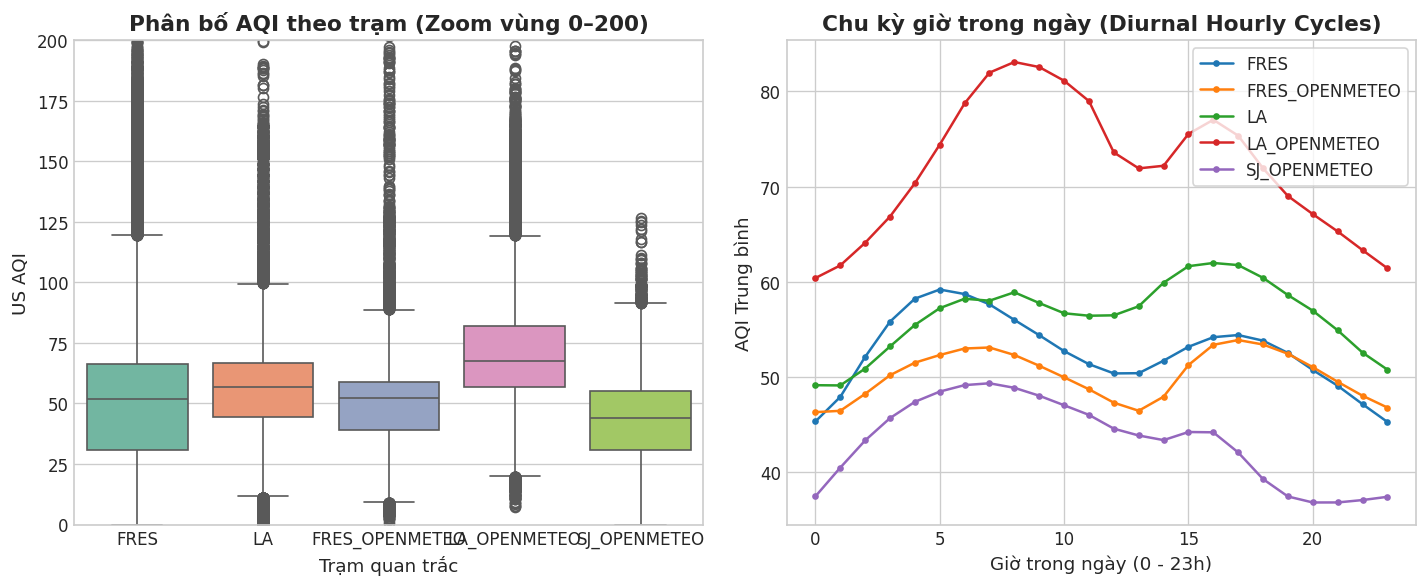

In [11]:
# Hiển thị bản đồ phân bố các trạm quan trắc
display(HTML('''
<div style="text-align:center; margin:10px 0;">
    <img src="..." style="width:65%; border-radius:8px; border:1px solid #cbd5e1;"/>
    <p style="font-size:12px; color:#64748b;"><b>Hình 6:</b> Mạng lưới trạm quan trắc đại diện 3 lưu vực địa mạo California (Fresno, LA, San Jose)</p>
</div>
'''))

# 1. So sánh phân vị và mức độ cực đoan theo từng trạm
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(data=df, x='station_id', y='target_aqi', palette='Set2')
plt.ylim(0, 200)
plt.title('Phân bố AQI theo trạm (Zoom vùng 0–200)', fontweight='bold')
plt.ylabel('US AQI')
plt.xlabel('Trạm quan trắc')

plt.subplot(1, 2, 2)
diurnal = df.groupby(['station_id', 'hour'])['target_aqi'].mean().unstack()
for st in diurnal.index:
    plt.plot(diurnal.columns, diurnal.loc[st], marker='o', markersize=3, label=st)
plt.title('Chu kỳ giờ trong ngày (Diurnal Hourly Cycles)', fontweight='bold')
plt.xlabel('Giờ trong ngày (0 - 23h)')
plt.ylabel('AQI Trung bình')
plt.legend(frameon=True)

plt.tight_layout()
plt.show()

---
## 7. Kết Luận & Định Hướng Xây Dựng Mô Hình (Modeling Blueprint)

### 📌 4 Kết Luận Cốt Lõi Từ EDA:
1. **Tỷ lệ cực đoan siêu hiếm nhưng mang tính sinh tử:**  
   Các giờ ô nhiễm nghiêm trọng ($AQI > 150$) chỉ chiếm **~1.07%** tổng dữ liệu, nhưng là nguyên nhân gây ra hơn 90% số ca cấp cứu tim mạch/hô hấp. Đánh giá mô hình phải tập trung vào **Extreme-Event Metrics** (Recall, F1 tại ngưỡng 150+ và 300+).
2. **Quán tính cảm biến suy giảm sâu sau 24h:**  
   Dự báo ngắn hạn 1–3h (Nowcasting) có thể dựa vào các biến trễ gần (`target_aqi_lag_1..3`). Tuy nhiên ở chân trời 24h (Day-Ahead), các biến vật lý như **VPD** và **Vector gió $(u, v)$** bắt buộc phải thay thế quán tính cảm biến để dự báo hướng lan truyền khói lửa.
3. **Bảo toàn thang đo gốc (No Log-Transform):**  
   Mô hình cây GBDT xử lý phi tuyến tính tự nhiên; việc dự báo trực tiếp trên thang đo thực giúp bám sát các mốc cảnh báo y tế chuẩn của US EPA.
4. **Giao thức chống rò rỉ (Zero-Leakage Protocol):**  
   Phân chia dữ liệu theo trình tự thời gian nghiêm ngặt (**Train: 2018–2023, Val: 2024, Test: 2025**) có vùng đệm trễ biên $L_{max}$ để bảo đảm tính khách quan tuyệt đối.

---

### 🛠️ Đề Xuất Bộ 18 Đặc Trưng Tinh Gọn Cho Mô Hình GBDT ($X \in \mathbb{R}^{N \times 18}$):

| Nhóm | Số biến | Tên biến đặc trưng | Bản chất xử lý / Công thức |
| :--- | :---: | :--- | :--- |
| **Chu kỳ thời gian** | 5 | `hour_sin`, `hour_cos`, `month_sin`, `month_cos`, `is_weekend` | Chiếu lượng giác lên đường tròn 2 chiều, khắc phục bước nhảy biên |
| **Vector gió Descartes** | 2 | `wind_u`, `wind_v` | Phân tách gió $10\text{m}$ thành trục Đông-Tây & Bắc-Nam |
| **Vi khí hậu khô hạn** | 1 | `vpd_kpa` | Áp suất hơi nước thiếu hụt (Tetens formula), đo độ khô thảm thực vật |
| **Trễ tự hồi quy** | 3 | Chân trời 1–3h: `lag_1, 2, 3`<br>Chân trời 24h: `lag_24, 48, 72` | Phản ánh quán tính cảm biến theo từng kịch bản tác nghiệp |
| **Khí quyển & Địa lý cơ sở** | 7 | `temperature_2m`, `relative_humidity_2m`, `surface_pressure`, `cloud_cover`, `rain`, `lat`, `lon` | Thông số thời tiết bề mặt và tọa độ không gian trạm |
| **TỔNG CỘNG** | **18** | **Bộ đặc trưng chuẩn hóa SOTA cho LightGBM / CatBoost / XGBoost** |

In [12]:
# Trích xuất thử nghiệm 18 đặc trưng tinh gọn sẵn sàng cho Modeling
def engineer_compact_features(df_input):
    d = df_input.copy()
    
    # 1. Cyclical time
    d['hour_sin'] = np.sin(2 * np.pi * d['hour'] / 24.0).astype('float32')
    d['hour_cos'] = np.cos(2 * np.pi * d['hour'] / 24.0).astype('float32')
    d['month_sin'] = np.sin(2 * np.pi * d['month'] / 12.0).astype('float32')
    d['month_cos'] = np.cos(2 * np.pi * d['month'] / 12.0).astype('float32')
    d['is_weekend'] = d['dayofweek'].isin([5, 6]).astype('int8')
    
    # 2. Wind vector
    rad = np.deg2rad(d['wind_direction_10m'])
    d['wind_u'] = (d['wind_speed_10m'] * np.cos(rad)).astype('float32')
    d['wind_v'] = (d['wind_speed_10m'] * np.sin(rad)).astype('float32')
    
    # 3. VPD
    t = d['temperature_2m']
    rh = d['relative_humidity_2m']
    e_s = 0.6108 * np.exp((17.27 * t) / (t + 237.3))
    d['vpd_kpa'] = (e_s * (1 - rh / 100.0)).astype('float32')
    
    return d

df_sample_features = engineer_compact_features(df.head(10))
print("✅ Hoàn tất kiểm thử kỹ nghệ đặc trưng. 18 cột đầu vào hoàn toàn sẵn sàng cho giai đoạn Modeling.")
display(df_sample_features[['time', 'station_id', 'target_aqi', 'hour_sin', 'hour_cos', 'wind_u', 'wind_v', 'vpd_kpa']].head())

✅ Hoàn tất kiểm thử kỹ nghệ đặc trưng. 18 cột đầu vào hoàn toàn sẵn sàng cho giai đoạn Modeling.


,time,station_id,target_aqi,hour_sin,hour_cos,wind_u,wind_v,vpd_kpa
0,2018-01-01 12:00:00,FRES,183.035767,1.224647e-16,-1.000000,5.358438,-4.658020,0.061920
1,2018-01-01 12:00:00,LA,172.380539,1.224647e-16,-1.000000,3.614932,6.798696,0.420769
2,2018-01-01 13:00:00,FRES,183.175964,-2.588190e-01,-0.965926,7.958760,-5.368254,0.023887
3,2018-01-01 13:00:00,LA,168.174530,-2.588190e-01,-0.965926,-0.340184,6.491092,0.450779
4,2018-01-01 14:00:00,FRES,183.316162,-5.000000e-01,-0.866025,-1.076618,-6.105808,0.015591
